# Citi Field TLC Pickup EDA — Data Inspection and Filtering

This notebook inspects the monthly TLC parquet files, verifies their coverage, and creates a combined Citi Field pickup catchment table using pickup zones 93 and 253. It then creates 15-minute pickup counts and compares activity around Mets games.

## 1. Imports and file paths

Because this notebook is stored in `notebooks/`, the parquet folder is one level above it.

In [11]:
from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq

DATA_DIR = Path("../high-vol-data")
CITI_FIELD_ZONES = {93, 253}
files = sorted(DATA_DIR.glob("*.parquet"))

print("Number of parquet files:", len(files))
for file in files:
    print(file.name)

if not files:
    raise FileNotFoundError(f"No parquet files found in {DATA_DIR.resolve()}")

Number of parquet files: 12
fhvhv_tripdata_2024-01.parquet
fhvhv_tripdata_2024-02.parquet
fhvhv_tripdata_2024-03.parquet
fhvhv_tripdata_2024-04.parquet
fhvhv_tripdata_2024-05.parquet
fhvhv_tripdata_2024-06.parquet
fhvhv_tripdata_2024-07.parquet
fhvhv_tripdata_2024-08.parquet
fhvhv_tripdata_2024-09.parquet
fhvhv_tripdata_2024-10.parquet
fhvhv_tripdata_2024-11.parquet
fhvhv_tripdata_2024-12.parquet


## 2. Inspect one file

This confirms the available fields and data types before processing every month.

In [12]:
sample_file = files[0]
table = pq.ParquetFile(sample_file)

print("Columns:")
print(table.schema.names)

sample = pd.read_parquet(
    sample_file,
    columns=["pickup_datetime", "PULocationID", "DOLocationID"]
)

print(sample.head())
print(sample.dtypes)

Columns:
['hvfhs_license_num', 'dispatching_base_num', 'originating_base_num', 'request_datetime', 'on_scene_datetime', 'pickup_datetime', 'dropoff_datetime', 'PULocationID', 'DOLocationID', 'trip_miles', 'trip_time', 'base_passenger_fare', 'tolls', 'bcf', 'sales_tax', 'congestion_surcharge', 'airport_fee', 'tips', 'driver_pay', 'shared_request_flag', 'shared_match_flag', 'access_a_ride_flag', 'wav_request_flag', 'wav_match_flag']
      pickup_datetime  PULocationID  DOLocationID
0 2024-01-01 00:28:08           161           158
1 2024-01-01 00:12:53           137            79
2 2024-01-01 00:23:05            79           186
3 2024-01-01 00:41:04           234           148
4 2024-01-01 00:57:21           148            97
pickup_datetime    datetime64[us]
PULocationID                int32
DOLocationID                int32
dtype: object


## 3. Check monthly coverage and timestamp quality

In [13]:
monthly_checks = []

for file in files:
    month_df = pd.read_parquet(
        file,
        columns=["pickup_datetime", "PULocationID"]
    )
    month_df["pickup_datetime"] = pd.to_datetime(
        month_df["pickup_datetime"], errors="coerce"
    )
    monthly_checks.append({
        "file": file.name,
        "rows": len(month_df),
        "start": month_df["pickup_datetime"].min(),
        "end": month_df["pickup_datetime"].max(),
        "missing_timestamps": month_df["pickup_datetime"].isna().sum(),
    })

monthly_checks = pd.DataFrame(monthly_checks)
display(monthly_checks)

,file,rows,start,end,missing_timestamps
0,fhvhv_tripdata_2024-01.parquet,19663930,2024-01-01,2024-01-31 23:59:59,0
1,fhvhv_tripdata_2024-02.parquet,19359148,2024-02-01,2024-02-29 23:59:59,0
2,fhvhv_tripdata_2024-03.parquet,21280788,2024-03-01,2024-03-31 23:59:59,0
3,fhvhv_tripdata_2024-04.parquet,19733038,2024-04-01,2024-04-30 23:59:59,0
4,fhvhv_tripdata_2024-05.parquet,20704538,2024-05-01,2024-05-31 23:59:59,0
5,fhvhv_tripdata_2024-06.parquet,20123226,2024-06-01,2024-06-30 23:59:59,0
6,fhvhv_tripdata_2024-07.parquet,19182934,2024-07-01,2024-07-31 23:59:59,0
7,fhvhv_tripdata_2024-08.parquet,19128392,2024-08-01,2024-08-31 23:59:59,0
8,fhvhv_tripdata_2024-09.parquet,19209788,2024-09-01,2024-09-30 23:59:59,0
9,fhvhv_tripdata_2024-10.parquet,20028282,2024-10-01,2024-10-31 23:59:59,0


## 4. Count pickups in the Citi Field catchment by month

This checks both TLC pickup zones used for the Citi Field catchment: zone 93 (Flushing Meadows-Corona Park/Citi Field) and zone 253 (Willets Point).

In [14]:
zone_checks = []

for file in files:
    zone_df = pd.read_parquet(file, columns=["PULocationID"])
    zone_counts = zone_df["PULocationID"].value_counts()
    zone_checks.append({
        "file": file.name,
        "zone_93_pickups": int(zone_counts.get(93, 0)),
        "zone_253_pickups": int(zone_counts.get(253, 0)),
        "combined_catchment_pickups": int(zone_counts.reindex(CITI_FIELD_ZONES, fill_value=0).sum()),
    })

zone_checks = pd.DataFrame(zone_checks)
display(zone_checks)

,file,zone_93_pickups,zone_253_pickups,combined_catchment_pickups
0,fhvhv_tripdata_2024-01.parquet,5350,430,5780
1,fhvhv_tripdata_2024-02.parquet,5331,422,5753
2,fhvhv_tripdata_2024-03.parquet,7753,644,8397
3,fhvhv_tripdata_2024-04.parquet,13167,762,13929
4,fhvhv_tripdata_2024-05.parquet,21144,882,22026
5,fhvhv_tripdata_2024-06.parquet,25035,970,26005
6,fhvhv_tripdata_2024-07.parquet,18814,1207,20021
7,fhvhv_tripdata_2024-08.parquet,34600,1146,35746
8,fhvhv_tripdata_2024-09.parquet,29163,1061,30224
9,fhvhv_tripdata_2024-10.parquet,15247,919,16166


## Preparing Citi Field Catchment Pickup Data

This section loads the monthly TLC parquet files, keeps the pickup time and pickup-zone columns, filters records to zones 93 and 253, combines the monthly data, and counts pickups in 15-minute intervals. The per-zone counts remain available so activity inside each TLC zone can also be compared.

In [15]:
chunks = []

for file in files:
    month_df = pd.read_parquet(
        file,
        columns=["pickup_datetime", "PULocationID"]
    )
    month_df["pickup_datetime"] = pd.to_datetime(
        month_df["pickup_datetime"], errors="coerce"
    )
    month_df = month_df[
        month_df["PULocationID"].isin(CITI_FIELD_ZONES)
        & month_df["pickup_datetime"].notna()
    ].copy()
    chunks.append(month_df)

citi_trips = pd.concat(chunks, ignore_index=True)

print("Citi Field catchment pickups:", len(citi_trips))
print("Pickups by TLC zone:")
display(citi_trips["PULocationID"].value_counts().sort_index())
display(citi_trips.head())

Citi Field catchment pickups: 201826
Pickups by TLC zone:


PULocationID
93     192516
253      9310
Name: count, dtype: int64

,pickup_datetime,PULocationID
0,2024-01-01 00:41:28,93
1,2024-01-01 00:49:03,93
2,2024-01-01 00:43:59,93
3,2024-01-01 00:36:07,93
4,2024-01-01 00:55:25,93


## 6. Create 15-minute pickup counts

Each pickup from either catchment zone is assigned to the 15-minute interval when it began. `pickup_counts` combines zones 93 and 253; `pickup_counts_by_zone` keeps their counts separate.

In [16]:
citi_trips["time_bin"] = citi_trips["pickup_datetime"].dt.floor("15min")

pickup_counts = (
    citi_trips
    .groupby("time_bin")
    .size()
    .reset_index(name="pickup_count")
    .sort_values("time_bin")
)

pickup_counts_by_zone = (
    citi_trips
    .groupby(["time_bin", "PULocationID"])
    .size()
    .reset_index(name="pickup_count")
    .sort_values(["time_bin", "PULocationID"])
)

print("Combined catchment pickup counts:")
display(pickup_counts.head())
print("Per-zone pickup counts:")
display(pickup_counts_by_zone.head())
print("Highest-volume combined 15-minute intervals:")
display(pickup_counts.sort_values("pickup_count", ascending=False).head(10))

Combined catchment pickup counts:


,time_bin,pickup_count
0,2024-01-01 00:00:00,5
1,2024-01-01 00:15:00,1
2,2024-01-01 00:30:00,10
3,2024-01-01 00:45:00,8
4,2024-01-01 01:00:00,5


Per-zone pickup counts:


,time_bin,PULocationID,pickup_count
0,2024-01-01 00:00:00,93,5
1,2024-01-01 00:15:00,93,1
2,2024-01-01 00:30:00,93,10
3,2024-01-01 00:45:00,93,8
4,2024-01-01 01:00:00,93,5


Highest-volume combined 15-minute intervals:


,time_bin,pickup_count
15205,2024-07-21 23:00:00,193
15206,2024-07-21 23:15:00,181
15029,2024-07-19 23:15:00,175
13091,2024-06-25 22:45:00,167
18944,2024-09-05 00:30:00,163
9603,2024-05-13 22:45:00,161
15030,2024-07-19 23:30:00,158
22370,2024-10-16 23:00:00,158
15929,2024-07-30 21:45:00,155
22371,2024-10-16 23:15:00,154


## 7. Check for Missing Values


In [17]:
events_file = Path("../citi_field_events_2024.csv")
events = pd.read_csv(events_file)

missing_by_column = events.isna().sum()
print("Missing values by column:")
display(missing_by_column)
print("Total missing entries:", int(missing_by_column.sum()))

Missing values by column:


event_id             0
event_type           0
event_name           0
event_date           0
venue                0
venue_zone_id        0
opponent             4
start_time_local     0
attendance          85
duration_minutes     4
mlb_game_id          4
end_time_local       4
dtype: int64

Total missing entries: 101


## 8. Prepare Event Time Ranges

This section converts game start and end times into timezone-aware datetimes, checks that the game records are valid, and creates a window from 30 minutes before first pitch to 90 minutes after the game ends. Concert rows are held out of this game-window analysis until concert durations are available.

In [18]:
events_prepared = events.copy()

events_prepared["start_time_dt"] = pd.to_datetime(
    events_prepared["start_time_local"], utc=True, errors="coerce"
)
events_prepared["end_time_dt"] = pd.to_datetime(
    events_prepared["end_time_local"], utc=True, errors="coerce"
)

game_events = events_prepared[events_prepared["event_type"] == "game"].copy()
invalid_times = (
    game_events["start_time_dt"].isna()
    | game_events["end_time_dt"].isna()
    | (game_events["end_time_dt"] <= game_events["start_time_dt"])
)
duplicate_ids = game_events["event_id"].duplicated().sum()
wrong_venue = (game_events["venue"] != "Citi Field").sum()

print("Invalid or reversed time ranges:", int(invalid_times.sum()))
print("Duplicate event IDs:", int(duplicate_ids))
print("Events outside Citi Field:", int(wrong_venue))

game_events["window_start"] = game_events["start_time_dt"] - pd.Timedelta(minutes=30)
game_events["window_end"] = game_events["end_time_dt"] + pd.Timedelta(minutes=90)

display(
    game_events[
        ["event_id", "event_date", "opponent", "start_time_dt",
         "end_time_dt", "window_start", "window_end"]
    ].head()
)

Invalid or reversed time ranges: 0
Duplicate event IDs: 0
Events outside Citi Field: 0


,event_id,event_date,opponent,start_time_dt,end_time_dt,window_start,window_end
0,METS_20240329_745848,2024-03-29,Milwaukee Brewers,2024-03-29 17:40:00+00:00,2024-03-29 20:08:00+00:00,2024-03-29 17:10:00+00:00,2024-03-29 21:38:00+00:00
1,METS_20240330_745850,2024-03-30,Milwaukee Brewers,2024-03-30 17:40:00+00:00,2024-03-30 20:30:00+00:00,2024-03-30 17:10:00+00:00,2024-03-30 22:00:00+00:00
2,METS_20240331_745845,2024-03-31,Milwaukee Brewers,2024-03-31 17:40:00+00:00,2024-03-31 20:23:00+00:00,2024-03-31 17:10:00+00:00,2024-03-31 21:53:00+00:00
3,METS_20240401_745842,2024-04-01,Detroit Tigers,2024-04-01 23:10:00+00:00,2024-04-02 01:56:00+00:00,2024-04-01 22:40:00+00:00,2024-04-02 03:26:00+00:00
4,METS_20240404_745844,2024-04-04,Detroit Tigers,2024-04-04 16:10:00+00:00,2024-04-04 19:35:00+00:00,2024-04-04 15:40:00+00:00,2024-04-04 21:05:00+00:00


## 9. Match Pickup Counts to Events

This section compares each 15-minute pickup interval with the prepared Mets game times. Concerts are excluded until their durations are available. Intervals are labeled `before_game` if they fall within the 30 minutes before first pitch, `during_game` from start through end, `after_game` within 90 minutes after the game, or `no_event` otherwise. Matched intervals retain the event ID, date, and opponent.

In [19]:
pickup_event_matches = pickup_counts.copy()

# TLC pickup timestamps are local New York times. Convert them to the same
# timezone-aware representation used by the event timestamps.
pickup_event_matches["pickup_time_dt"] = (
    pd.to_datetime(pickup_event_matches["time_bin"], errors="coerce")
    .dt.tz_localize("America/New_York", ambiguous="NaT", nonexistent="NaT")
)

pickup_event_matches["event_id"] = pd.NA
pickup_event_matches["event_date"] = pd.NA
pickup_event_matches["opponent"] = pd.NA
pickup_event_matches["event_phase"] = "no_event"

# Assign the most specific phase first. This prevents an overlapping event
# window from replacing an already assigned game interval.
for phase, start_column, end_column in [
    ("during_game", "start_time_dt", "end_time_dt"),
    ("before_game", "window_start", "start_time_dt"),
    ("after_game", "end_time_dt", "window_end"),
]:
    for _, event in game_events.iterrows():
        in_phase = (
            (pickup_event_matches["pickup_time_dt"] >= event[start_column])
            & (pickup_event_matches["pickup_time_dt"] < event[end_column])
            & pickup_event_matches["event_phase"].eq("no_event")
        )
        pickup_event_matches.loc[in_phase, "event_id"] = event["event_id"]
        pickup_event_matches.loc[in_phase, "event_date"] = event["event_date"]
        pickup_event_matches.loc[in_phase, "opponent"] = event["opponent"]
        pickup_event_matches.loc[in_phase, "event_phase"] = phase

print("Pickup intervals by event phase:")
display(pickup_event_matches["event_phase"].value_counts())
display(
    pickup_event_matches[
        ["time_bin", "pickup_count", "event_id", "event_date",
         "opponent", "event_phase"]
    ].query("event_phase != 'no_event'").head(10)
)

Pickup intervals by event phase:


event_phase
no_event       26795
during_game      925
after_game       498
before_game      166
Name: count, dtype: int64

,time_bin,pickup_count,event_id,event_date,opponent,event_phase
6134,2024-03-29 13:15:00,7,METS_20240329_745848,2024-03-29,Milwaukee Brewers,before_game
6135,2024-03-29 13:30:00,1,METS_20240329_745848,2024-03-29,Milwaukee Brewers,before_game
6136,2024-03-29 13:45:00,8,METS_20240329_745848,2024-03-29,Milwaukee Brewers,during_game
6137,2024-03-29 14:00:00,13,METS_20240329_745848,2024-03-29,Milwaukee Brewers,during_game
6138,2024-03-29 14:15:00,9,METS_20240329_745848,2024-03-29,Milwaukee Brewers,during_game
6139,2024-03-29 14:30:00,6,METS_20240329_745848,2024-03-29,Milwaukee Brewers,during_game
6140,2024-03-29 14:45:00,9,METS_20240329_745848,2024-03-29,Milwaukee Brewers,during_game
6141,2024-03-29 15:00:00,14,METS_20240329_745848,2024-03-29,Milwaukee Brewers,during_game
6142,2024-03-29 15:15:00,15,METS_20240329_745848,2024-03-29,Milwaukee Brewers,during_game
6143,2024-03-29 15:30:00,22,METS_20240329_745848,2024-03-29,Milwaukee Brewers,during_game


## 10. Compare Pickup Counts by Game Phase

This section summarizes and compares the observed 15-minute pickup counts before, during, and after Mets games. It reports the average and median for each phase and plots the average counts. Because `pickup_counts` includes only intervals with at least one recorded pickup, these summaries do not include zero-pickup intervals.

Pickup counts by event phase:


,intervals,average_pickups,median_pickups
event_phase,,,
before_game,166,8.31,6.0
during_game,925,23.44,14.0
after_game,498,52.77,46.5


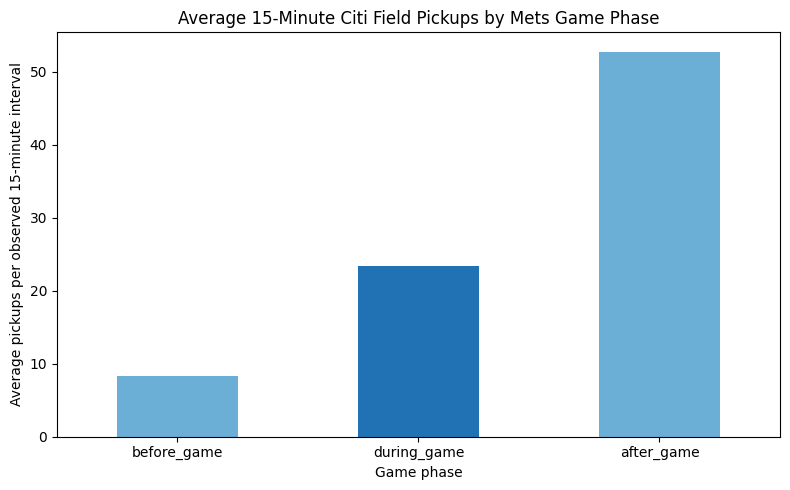

In [20]:
import matplotlib.pyplot as plt

phase_order = ["before_game", "during_game", "after_game"]
game_phase_counts = pickup_event_matches[
    pickup_event_matches["event_phase"].isin(phase_order)
]

phase_summary = (
    game_phase_counts
    .groupby("event_phase")["pickup_count"]
    .agg(intervals="count", average_pickups="mean", median_pickups="median")
    .reindex(phase_order)
)

print("Pickup counts by event phase:")
display(phase_summary.round(2))

ax = phase_summary["average_pickups"].plot(
    kind="bar",
    figsize=(8, 5),
    color=["#6baed6", "#2171b5", "#6baed6"],
    rot=0,
)
ax.set_title("Average 15-Minute Citi Field Pickups by Mets Game Phase")
ax.set_xlabel("Game phase")
ax.set_ylabel("Average pickups per observed 15-minute interval")
plt.tight_layout()
plt.show()